# QuickCart Warehouse Inventory Stockout Risk
## Supervised Machine Learning Classification Project

**Institution:** The Unlox Academy  
**Project type:** Multi-table, 3-class supervised classification  
**Target:** `stockout_risk` — Safe / At-Risk / Imminent  
**Dataset period:** 1–30 October 2026

### Business objective
Predict stockout risk for each SKU at each store on each day so the inventory team can prioritise replenishment, reduce lost sales, and avoid unnecessary over-ordering.

### Submission contents
This notebook includes data loading, data-quality checks, relational joins, feature engineering, a time-based train/test split, baseline and model comparisons, evaluation, interpretation, and business recommendations.

## 1. Imports and reproducibility

The project uses pandas and scikit-learn. The data files are stored in the `data/` folder alongside this notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)

## 2. Load the five source tables

The supplier file deliberately contains the text value `N/A`. We explicitly list common missing-value tokens rather than relying only on pandas' implicit defaults.

In [2]:
DATA_DIR = "data"

events = pd.read_csv(f"{DATA_DIR}/dim_events.csv",
                     na_values=["N/A", "missing", "--", "NA", "null"],
                     keep_default_na=True)
skus = pd.read_csv(f"{DATA_DIR}/dim_skus.csv",
                   na_values=["N/A", "missing", "--", "NA", "null"],
                   keep_default_na=True)
stores = pd.read_csv(f"{DATA_DIR}/dim_stores.csv",
                     na_values=["N/A", "missing", "--", "NA", "null"],
                     keep_default_na=True)
suppliers = pd.read_csv(f"{DATA_DIR}/dim_suppliers.csv",
                        na_values=["N/A", "missing", "--", "NA", "null"],
                        keep_default_na=True)
fact = pd.read_csv(f"{DATA_DIR}/fact_inventory_daily.csv",
                   na_values=["N/A", "missing", "--", "NA", "null"],
                   keep_default_na=True)

events["date"] = pd.to_datetime(events["date"])
fact["date"] = pd.to_datetime(fact["date"])

tables = {
    "dim_stores": stores,
    "dim_skus": skus,
    "dim_suppliers": suppliers,
    "dim_events": events,
    "fact_inventory_daily": fact
}
pd.DataFrame({"table": list(tables.keys()),
              "rows": [len(x) for x in tables.values()],
              "columns": [len(x.columns) for x in tables.values()]})

,table,rows,columns
0,dim_stores,12,8
1,dim_skus,60,9
2,dim_suppliers,15,6
3,dim_events,30,5
4,fact_inventory_daily,21600,16


## 3. Data validation and quality checks

The brief provides locked row counts, target distribution, date range, and operational sanity checks. The checks below compare the loaded data with those expected values before modeling.

In [3]:
expected_rows = {
    "dim_stores": 12,
    "dim_skus": 60,
    "dim_suppliers": 15,
    "dim_events": 30,
    "fact_inventory_daily": 21600
}
row_check = pd.DataFrame({
    "table": expected_rows.keys(),
    "expected_rows": expected_rows.values(),
    "actual_rows": [len(tables[k]) for k in expected_rows],
})
row_check["pass"] = row_check["expected_rows"] == row_check["actual_rows"]
display(row_check)

target_check = fact["stockout_risk"].value_counts().reindex(
    ["Safe", "At-Risk", "Imminent"], fill_value=0
).to_frame("rows")
target_check["share_pct"] = (target_check["rows"] / len(fact) * 100).round(2)
display(target_check)

print("Date range:", fact["date"].min().date(), "to", fact["date"].max().date())
print("Unique dates:", fact["date"].nunique())
print("Missing actual lead time:", fact["lead_time_days_actual"].isna().sum())
print("Missing supplier reliability after explicit NA parsing:",
      suppliers["reliability_score"].isna().sum())
print("City values vs display labels:", stores["city"].nunique(),
      "canonical cities;", stores["city_display"].nunique(), "display labels")

,table,expected_rows,actual_rows,pass
0,dim_stores,12,12,True
1,dim_skus,60,60,True
2,dim_suppliers,15,15,True
3,dim_events,30,30,True
4,fact_inventory_daily,21600,21600,True


,rows,share_pct
stockout_risk,,
Safe,14131,65.42
At-Risk,5186,24.01
Imminent,2283,10.57


Date range: 2026-10-01 to 2026-10-30
Unique dates: 30
Missing actual lead time: 19899
Missing supplier reliability after explicit NA parsing: 3
City values vs display labels: 6 canonical cities; 8 display labels


### Data-quality observations

- `city` is the clean join/grouping field. `city_display` contains two casing inconsistencies and should be standardised for presentation.
- Three supplier reliability values are encoded as the literal `N/A` in the source CSV. They are treated as missing values and imputed during feature engineering.
- `lead_time_days_actual` is missing on most rows because it is populated only when a reorder is placed. It is excluded from the predictive features because it is not reliably available at scoring time.

In [4]:
# Standardise the display-only city field for reporting.
stores["city_display_clean"] = stores["city_display"].astype("string").str.strip().str.title()
display(stores[["store_id", "city", "city_display", "city_display_clean"]]
        .loc[stores["city_display"] != stores["city_display_clean"]])

# Locked target and event checks
fact["is_imminent"] = fact["stockout_risk"].eq("Imminent")
festival_rates = fact.groupby("is_festival_week")["is_imminent"].mean().mul(100).round(2)
print("Imminent rate by festival flag (%):")
display(festival_rates.rename(index={"N":"Non-festival", "Y":"Festival"}).to_frame("rate_pct"))

perishable_join = fact.merge(skus[["sku_id","is_perishable"]], on="sku_id", how="left")
print("Imminent rate by perishability (%):")
display((perishable_join.groupby("is_perishable")["is_imminent"].mean()*100)
        .round(2).to_frame("rate_pct"))

,store_id,city,city_display,city_display_clean
2,ST03,Bengaluru,BENGALURU,Bengaluru
8,ST09,Hyderabad,hyderabad,Hyderabad


Imminent rate by festival flag (%):


,rate_pct
is_festival_week,
Non-festival,9.51
Festival,23.31


Imminent rate by perishability (%):


,rate_pct
is_perishable,
N,9.30
Y,12.77


## 4. Join the relational tables

The fact table has one row per `(store_id, sku_id, date)`. The four dimension tables enrich it with store, product, supplier, and event information. Many-to-one validation ensures that joins do not multiply fact rows.

In [5]:
data = (
    fact.merge(stores, on="store_id", how="left", validate="many_to_one")
        .merge(skus, on=["sku_id", "supplier_id"], how="left", validate="many_to_one")
        .merge(suppliers, on="supplier_id", how="left", validate="many_to_one",
               suffixes=("", "_supplier"))
        .merge(events, on="date", how="left", validate="many_to_one")
)

print("Joined shape:", data.shape)
print("Unmatched SKU/category rows:", data["category"].isna().sum())
print("Unmatched event rows:", data["event_name"].isna().sum())
assert len(data) == len(fact), "Join changed fact-table row count."
display(data.head())

Joined shape: (21600, 41)
Unmatched SKU/category rows: 0
Unmatched event rows: 0


,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk,is_imminent,city,city_display,city_tier,store_size,sqft,opened_year,baseline_daily_orders,city_display_clean,sku_name,category,unit_price_inr,shelf_life_days,is_perishable,festive_relevant,popularity_tier,supplier_name,categories_supplied,reliability_score,base_lead_time_days,lead_time_variance_days,event_name,event_type,demand_multiplier_festive,demand_multiplier_other
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe,False,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Mumbai,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe,False,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Mumbai,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe,False,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Mumbai,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe,False,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Mumbai,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe,False,Mumbai,Mumbai,Tier1,Large,2946,2023,580,Mumbai,Banana 1kg,Fruits & Vegetables,132.04,2,Y,N,Low,Coastal Foods Pvt Ltd,"Snacks, Fruits & Vegetables",0.83,1,2.5,Regular Day,none,1.0,1.0


## 5. Exploratory analysis

The target is imbalanced: Safe is the majority class, while Imminent is the operationally critical minority class. Accuracy alone is therefore insufficient.

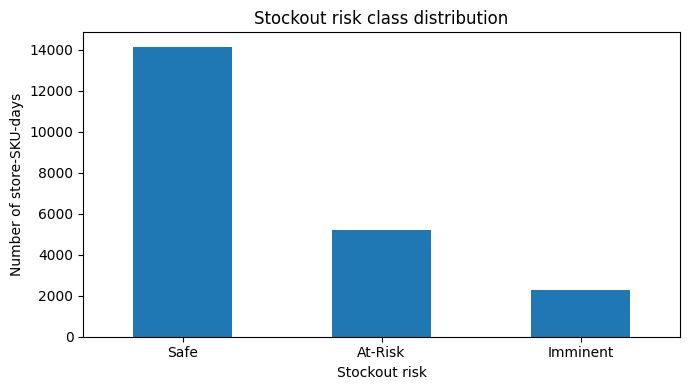

Imminent rate by festival flag (%):


,imminent_rate_pct
is_festival_week,
N,9.51
Y,23.31


Imminent rate by perishable flag (%):


,imminent_rate_pct
is_perishable,
N,9.30
Y,12.77


In [6]:
target_order = ["Safe", "At-Risk", "Imminent"]
target_counts = data["stockout_risk"].value_counts().reindex(target_order)
ax = target_counts.plot(kind="bar", figsize=(7,4), rot=0,
                        title="Stockout risk class distribution")
ax.set_xlabel("Stockout risk")
ax.set_ylabel("Number of store-SKU-days")
plt.tight_layout()
plt.show()

eda = data.assign(is_imminent=data["stockout_risk"].eq("Imminent"))
festival_summary = (eda.groupby("is_festival_week")["is_imminent"]
                    .mean().mul(100).round(2))
perishable_summary = (eda.groupby("is_perishable")["is_imminent"]
                      .mean().mul(100).round(2))
print("Imminent rate by festival flag (%):")
display(festival_summary.to_frame("imminent_rate_pct"))
print("Imminent rate by perishable flag (%):")
display(perishable_summary.to_frame("imminent_rate_pct"))

## 6. Feature engineering

Derived features follow the project brief:
- `reorder_gap`: reorder point minus closing stock.
- `days_of_cover_ratio`: days of cover divided by expected supplier lead time.
- `reliability_clean`: supplier reliability with missing values imputed by the median within SKU category.
- `recent_reorder_3d`: whether a reorder was placed in any of the previous three days for the same store-SKU pair.
- Calendar features: day of month, festival indicator, and days since the Diwali-week start.

`lead_time_days_actual` is deliberately excluded because it is mostly missing and is only known on reorder days.

In [7]:
data = data.sort_values(["store_id", "sku_id", "date"]).copy()

data["reliability_clean"] = data.groupby("category")["reliability_score"].transform(
    lambda s: s.fillna(s.median())
)
data["reorder_gap"] = data["reorder_point"] - data["closing_stock"]
data["days_of_cover_ratio"] = (
    data["days_of_cover"] / data["lead_time_days_expected"].replace(0, np.nan)
)
data["recent_reorder_3d"] = (
    data.groupby(["store_id", "sku_id"])["reorder_placed"]
        .transform(lambda s: s.shift(1).eq("Y").rolling(3, min_periods=1).max())
        .fillna(0).astype(int)
)
data["day_of_month"] = data["date"].dt.day
data["days_since_festival_start"] = (
    data["date"] - pd.Timestamp("2026-10-22")
).dt.days.clip(lower=0, upper=8)
data["is_festival_flag"] = data["is_festival_week"].map({"Y": 1, "N": 0})

display(data[["date","store_id","sku_id","reorder_gap","days_of_cover_ratio",
              "reliability_clean","recent_reorder_3d","day_of_month",
              "days_since_festival_start"]].head(10))

,date,store_id,sku_id,reorder_gap,days_of_cover_ratio,reliability_clean,recent_reorder_3d,day_of_month,days_since_festival_start
0,2026-10-01,ST01,SKU001,-108.5,9.66,0.83,0,1,0
1,2026-10-02,ST01,SKU001,-98.5,10.79,0.83,0,2,0
2,2026-10-03,ST01,SKU001,-83.5,8.99,0.83,0,3,0
3,2026-10-04,ST01,SKU001,-73.5,8.79,0.83,0,4,0
4,2026-10-05,ST01,SKU001,-64.5,8.55,0.83,0,5,0
5,2026-10-06,ST01,SKU001,-52.5,7.52,0.83,0,6,0
6,2026-10-07,ST01,SKU001,-43.5,6.99,0.83,0,7,0
7,2026-10-08,ST01,SKU001,-30.5,6.01,0.83,0,8,0
8,2026-10-09,ST01,SKU001,-18.5,4.81,0.83,0,9,0
9,2026-10-10,ST01,SKU001,-5.5,3.76,0.83,0,10,0


## 7. Time-based train/test split

To avoid leakage from repeated observations of the same store-SKU pair, the split follows the project specification:
- Training: 1–23 October 2026
- Testing: 24–30 October 2026

This also tests performance during the later part of the Diwali demand period.

In [8]:
train = data[data["date"] < "2026-10-24"].copy()
test = data[data["date"] >= "2026-10-24"].copy()

print("Train rows:", len(train), "|", train["date"].min().date(), "to", train["date"].max().date())
print("Test rows:", len(test), "|", test["date"].min().date(), "to", test["date"].max().date())

numeric_features = [
    "opening_stock", "units_demanded", "units_sold", "closing_stock",
    "reorder_point", "lead_time_days_expected", "sales_velocity_7d",
    "days_of_cover", "reorder_gap", "days_of_cover_ratio", "reliability_clean",
    "base_lead_time_days", "lead_time_variance_days", "unit_price_inr",
    "shelf_life_days", "sqft", "baseline_daily_orders", "opened_year",
    "demand_multiplier_festive", "demand_multiplier_other", "day_of_month",
    "days_since_festival_start", "recent_reorder_3d", "is_festival_flag"
]
categorical_features = [
    "category", "is_perishable", "festive_relevant", "popularity_tier",
    "store_size", "city", "event_type"
]
feature_cols = numeric_features + categorical_features
X_train, y_train = train[feature_cols], train["stockout_risk"]
X_test, y_test = test[feature_cols], test["stockout_risk"]

Train rows: 16560 | 2026-10-01 to 2026-10-23
Test rows: 5040 | 2026-10-24 to 2026-10-30


## 8. Preprocessing and model comparison

Numeric features are median-imputed and standardised. Categorical features are most-frequent imputed and one-hot encoded. All preprocessing is fitted inside each training pipeline to prevent test-set information from influencing training.

Models:
1. Majority-class baseline.
2. Class-weighted multinomial Logistic Regression.
3. Class-weighted Random Forest.

The Imminent class receives extra weight in the selected Random Forest because missing an imminent stockout is more costly than a false alarm.

In [9]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_features),
    ("categorical", categorical_pipe, categorical_features)
])

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=350, min_samples_leaf=2,
        class_weight={"Safe": 1, "At-Risk": 1, "Imminent": 3},
        max_features="sqrt", n_jobs=-1, random_state=RANDOM_STATE
    )
}

fitted_models = {}
predictions = {}
comparison_rows = []

for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    fitted_models[name] = pipe
    predictions[name] = y_pred
    report = classification_report(
        y_test, y_pred, labels=target_order, output_dict=True, zero_division=0
    )
    comparison_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Imminent precision": report["Imminent"]["precision"],
        "Imminent recall": report["Imminent"]["recall"],
        "Imminent F1": report["Imminent"]["f1-score"]
    })

comparison = pd.DataFrame(comparison_rows).set_index("Model").round(4)
display(comparison)

,Accuracy,Macro F1,Imminent precision,Imminent recall,Imminent F1
Model,,,,,
Majority baseline,0.6228,0.2559,0.0000,0.0000,0.0000
Logistic Regression,0.8147,0.6476,0.4724,0.9948,0.6406
Random Forest,0.9379,0.8829,0.8760,0.7019,0.7794


## 9. Selected model evaluation

The weighted Random Forest is selected based on its strong overall and macro-averaged performance while recovering a materially larger share of Imminent cases than the majority baseline. The confusion matrix makes the remaining missed Imminent cases visible.

              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.82      0.93      0.87      1126
    Imminent       0.88      0.70      0.78       775

    accuracy                           0.94      5040
   macro avg       0.90      0.88      0.88      5040
weighted avg       0.94      0.94      0.94      5040



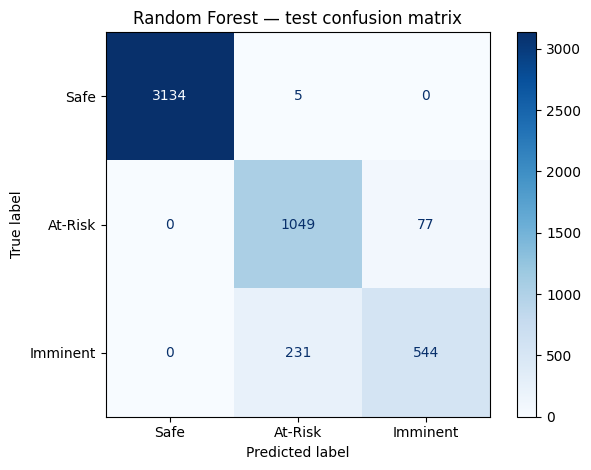

In [10]:
selected_name = "Random Forest"
selected_model = fitted_models[selected_name]
selected_pred = predictions[selected_name]

print(classification_report(
    y_test, selected_pred, labels=target_order, zero_division=0
))
cm = confusion_matrix(y_test, selected_pred, labels=target_order)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_order)
disp.plot(cmap="Blues", values_format="d")
plt.title("Random Forest — test confusion matrix")
plt.tight_layout()
plt.show()

## 10. Feature importance

Random Forest feature importance is used as a model-level diagnostic. It indicates which inputs the fitted model relied on most; it does not prove causation.

,importance
days_of_cover,0.233017
days_of_cover_ratio,0.229027
reorder_gap,0.192610
closing_stock,0.059265
opening_stock,0.030216
sales_velocity_7d,0.024526
recent_reorder_3d,0.021505
reorder_point,0.019960
reliability_clean,0.018065
lead_time_days_expected,0.017618


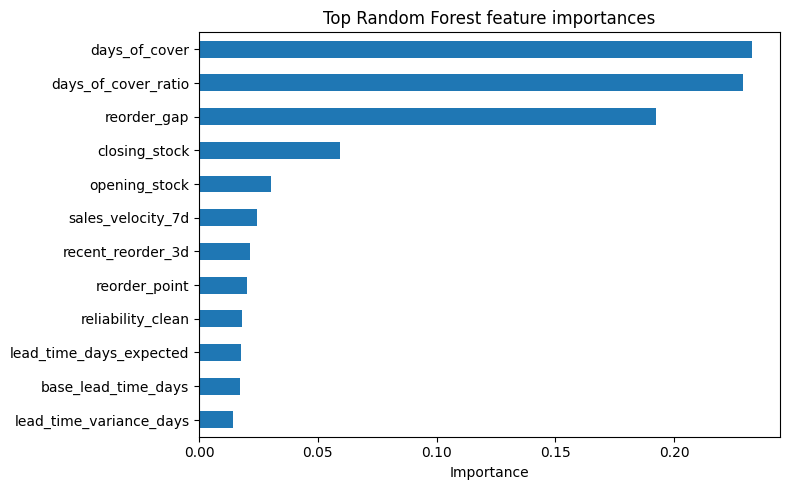

In [11]:
fitted_preprocessor = selected_model.named_steps["preprocess"]
onehot = fitted_preprocessor.named_transformers_["categorical"].named_steps["onehot"]
all_feature_names = numeric_features + list(onehot.get_feature_names_out(categorical_features))
importance = pd.Series(
    selected_model.named_steps["model"].feature_importances_,
    index=all_feature_names
).sort_values(ascending=False)

display(importance.head(15).to_frame("importance"))
importance.head(12).sort_values().plot(kind="barh", figsize=(8,5),
                                        title="Top Random Forest feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 11. Findings and business recommendations

### Key findings
- The target is imbalanced: Safe is the largest class and Imminent is the smallest.
- The Imminent rate is substantially higher during the festival period than on non-festival days.
- Perishable products show a higher Imminent rate than non-perishable products.
- Stock cover, cover relative to expected lead time, and the reorder gap are among the strongest model signals.
- The time-based test is deliberately difficult because it includes the back half of Diwali week.

### Recommendations
1. Use the model as a daily prioritisation aid, not as an automatic purchase-order system.
2. Put Imminent predictions at the top of the replenishment queue and monitor false negatives closely.
3. Increase safety-stock review frequency for festive-relevant SKUs before demand spikes.
4. Review supplier reliability and lead-time variance when setting buffers.
5. Track recall for Imminent, precision, macro F1, and confusion matrices after each retraining cycle.
6. Retrain on a longer time window when additional dates become available; this dataset contains only 30 days.

## 12. Limitations and conclusion

- The dataset covers only 30 days and 12 stores, so performance may not generalise to other seasons or new stores.
- A time-based holdout is more realistic than a random row split, but a single seven-day test window is still limited.
- The Imminent class is operationally important; the selected model still misses some Imminent observations. Human review and conservative replenishment rules remain necessary.
- Feature importance is associational, not causal.
- Actual lead time is excluded because it is missing by construction on most rows and may not be available when a prediction is made.

**Conclusion:** The Random Forest provides a strong classification result on the specified time-based test period and offers a practical way to rank daily stockout risk. Its Imminent recall should remain the primary operational metric.

## Appendix A. Reproducibility and environment

Suggested environment:
- Python 3.10+
- pandas
- numpy
- matplotlib
- scikit-learn
- jupyter

Run the notebook from the project folder so the relative `data/` paths resolve.